# Nom et prenom: GUERBATI Mohammed Abdelaziz
# M2 IMDS

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)   # fixed seed for reproducibility

# ---- Experimental parameters (chosen by me) ----
THETA   = 0.3                      # true threshold of the target function f_theta
EPSILON = 0.05                     # accuracy parameter
DELTA   = 0.05                     # confidence parameter
ETA     = 0.2                      # label-noise rate (agnostic setting)
SIZES   = [5, 10, 20, 50, 100, 200]  # training sample sizes m
N_REP   = 1000                     # repetitions per sample size
N_TEST  = 200_000                  # size of the independent test set

## 1. Data Generation

Points are drawn uniformly in $[0,1]$. In the realizable setting $y=f_\theta(x)$, with $f_\theta(x)=1$ iff $x>\theta$. In the agnostic setting each label is flipped independently with probability $\eta$.

In [2]:
def target(x, theta=THETA):
    """Target function f_theta(x) = 1 if x > theta else 0."""
    return (x > theta).astype(int)

def generate_data(m, theta=THETA, eta=0.0, rng=rng):
    """Sample m points uniformly in [0,1]; labels from f_theta, each flipped with prob. eta."""
    x = rng.uniform(0, 1, m)
    y = target(x, theta)
    if eta > 0:
        flip = rng.random(m) < eta
        y = np.where(flip, 1 - y, y)
    return x, y

# One dataset per sample size, in both settings
datasets_real = {m: generate_data(m, eta=0.0) for m in SIZES}
datasets_noisy = {m: generate_data(m, eta=ETA) for m in SIZES}

for m in SIZES:
    print(f"m={m:3d} | realizable: {datasets_real[m][1].sum():3d} positive labels"
          f" | noisy: {datasets_noisy[m][1].sum():3d} positive labels")

m=  5 | realizable:   4 positive labels | noisy:   2 positive labels
m= 10 | realizable:   9 positive labels | noisy:   5 positive labels
m= 20 | realizable:  15 positive labels | noisy:  14 positive labels
m= 50 | realizable:  33 positive labels | noisy:  36 positive labels
m=100 | realizable:  71 positive labels | noisy:  67 positive labels
m=200 | realizable: 136 positive labels | noisy: 119 positive labels


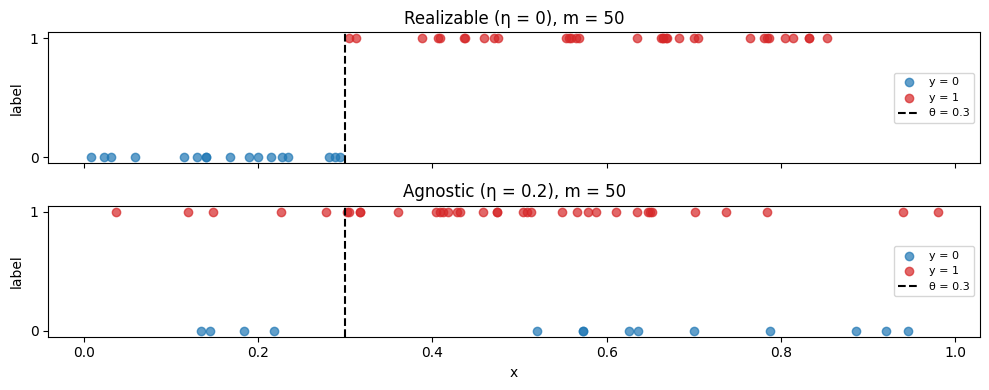

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
m_vis = 50
for ax, (title, (x, y)) in zip(axes, [("Realizable (η = 0)", datasets_real[m_vis]),
                                      (f"Agnostic (η = {ETA})", datasets_noisy[m_vis])]):
    ax.scatter(x[y == 0], np.zeros((y == 0).sum()), c="tab:blue", label="y = 0", alpha=0.7)
    ax.scatter(x[y == 1], np.ones((y == 1).sum()), c="tab:red", label="y = 1", alpha=0.7)
    ax.axvline(THETA, color="k", ls="--", label=f"θ = {THETA}")
    ax.set_yticks([0, 1]); ax.set_ylabel("label"); ax.set_title(f"{title}, m = {m_vis}")
    ax.legend(loc="center right", fontsize=8)
axes[1].set_xlabel("x")
plt.tight_layout(); plt.show()

**Comment.** In the realizable dataset all labels are separated perfectly by the dashed line at $\theta$. In the noisy dataset some points lie on the "wrong" side of $\theta$ because their label was flipped: no threshold can classify all of them correctly anymore.

## 2. Implementation of ERM

**Hypothesis class:** $\mathcal{H}=\{h_t : t\in[0,1]\}$ with $h_t(x)=\mathbb{1}[x>t]$.

**Strategy.** The empirical error of $h_t$ only changes when $t$ crosses a training point, so only $m+1$ distinct thresholds need to be examined. After sorting the points $x_{(1)}\le\dots\le x_{(m)}$, a threshold placed between $x_{(i)}$ and $x_{(i+1)}$ (for $i=0,\dots,m$) predicts $0$ for the first $i$ points and $1$ for the last $m-i$. Its number of errors is

$$\#\{j\le i : y_{(j)}=1\} \;+\; \#\{j> i : y_{(j)}=0\},$$

which is computed for all $i$ at once with cumulative sums (complexity $O(m\log m)$). ERM returns the $i$ with the smallest error, and the threshold is placed at the **midpoint** of the corresponding gap (using $0$ and $1$ as the outer bounds).

In [4]:
def erm_threshold(x, y):
    """ERM over threshold classifiers. Returns (best threshold, empirical error)."""
    order = np.argsort(x)
    xs, ys = x[order], y[order]
    m = len(xs)
    ones_left = np.concatenate(([0], np.cumsum(ys)))                 # positives among the first i points
    zeros_right = (m - np.arange(m + 1)) - (ones_left[-1] - ones_left)  # negatives among the last m-i points
    errors = (ones_left + zeros_right) / m                           # empirical error of each candidate gap
    best = np.argmin(errors)
    padded = np.concatenate(([0.0], xs, [1.0]))
    t = 0.5 * (padded[best] + padded[best + 1])                      # midpoint of the chosen gap
    return t, errors[best]

def predict(x, t):
    return (x > t).astype(int)

def error_rate(x, y, t):
    return np.mean(predict(x, t) != y)

# Sanity check against a brute-force search on a small dataset
x, y = datasets_noisy[20]
t_erm, e_erm = erm_threshold(x, y)
grid = np.linspace(0, 1, 10001)
e_brute = min(error_rate(x, y, t) for t in grid)
print(f"ERM: t = {t_erm:.3f}, empirical error = {e_erm:.3f} | brute force min error = {e_brute:.3f}")

ERM: t = 0.021, empirical error = 0.250 | brute force min error = 0.250


## 3. Performance Evaluation

The **true error** is estimated on a large independent test set (200 000 points) generated by the same distribution as the training data: clean labels in the realizable setting, labels flipped with probability $\eta$ in the agnostic setting.

In [5]:
x_test = rng.uniform(0, 1, N_TEST)
y_test_clean = target(x_test)
y_test_noisy = np.where(rng.random(N_TEST) < ETA, 1 - y_test_clean, y_test_clean)

rows = []
for setting, datasets, y_test in [("Realizable", datasets_real, y_test_clean),
                                  ("Agnostic", datasets_noisy, y_test_noisy)]:
    for m in SIZES:
        x, y = datasets[m]
        t, emp = erm_threshold(x, y)
        rows.append({"setting": setting, "m": m, "ERM threshold": round(t, 3),
                     "empirical error": emp, "true error (test)": error_rate(x_test, y_test, t)})
df_single = pd.DataFrame(rows)
df_single

,setting,m,ERM threshold,empirical error,true error (test)
0,Realizable,5,0.267,0.00,0.033265
1,Realizable,10,0.249,0.00,0.050505
2,Realizable,20,0.277,0.00,0.023130
3,Realizable,50,0.299,0.00,0.001305
4,Realizable,100,0.296,0.00,0.003710
5,Realizable,200,0.299,0.00,0.001150
6,Agnostic,5,0.901,0.00,0.561695
7,Agnostic,10,0.299,0.30,0.201315
8,Agnostic,20,0.021,0.25,0.366910
9,Agnostic,50,0.222,0.26,0.246790


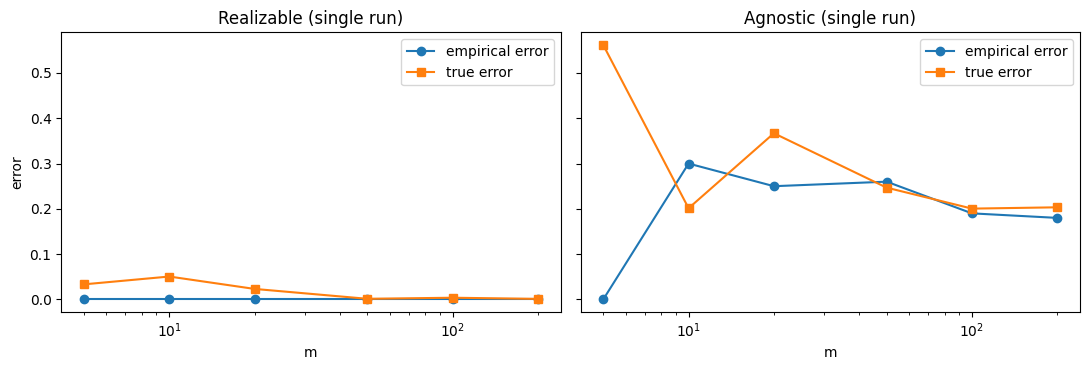

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, setting in zip(axes, ["Realizable", "Agnostic"]):
    d = df_single[df_single.setting == setting]
    ax.plot(d.m, d["empirical error"], "o-", label="empirical error")
    ax.plot(d.m, d["true error (test)"], "s-", label="true error")
    ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_title(f"{setting} (single run)")
    ax.legend()
axes[0].set_ylabel("error")
plt.tight_layout(); plt.show()

**Comment.** In the realizable setting the empirical error is always exactly $0$, because the target $f_\theta$ belongs to the class and ERM finds a consistent threshold. The true error is small (between about $0.001$ and $0.05$) and tends to decrease as $m$ grows, although a single run is not monotone (e.g. $m=10$ is worse than $m=5$). In the agnostic setting the empirical error is no longer $0$ (except by chance for the smallest $m$), and it is a poor and optimistic estimate of the true error for small samples: for $m=5$ ERM fits the noise perfectly (empirical error $0$) but its true error is about $0.56$. For large $m$ both errors get close to each other and to $\eta=0.2$. Single runs are very noisy (e.g. $m=20$), which motivates the repeated experiments below.

## 4. Experimental Verification of PAC Learning

For every $m$, the experiment is repeated `N_REP = 1000` times on fresh training sets, and we estimate $\Pr(L(h)>\varepsilon)$ with $\varepsilon=0.05$.

In [7]:
def run_experiment(eta, y_test):
    emp = {m: np.empty(N_REP) for m in SIZES}
    true = {m: np.empty(N_REP) for m in SIZES}
    for m in SIZES:
        for r in range(N_REP):
            x, y = generate_data(m, eta=eta)
            t, e = erm_threshold(x, y)
            emp[m][r] = e
            true[m][r] = error_rate(x_test, y_test, t)
    return emp, true

emp_real, true_real = run_experiment(0.0, y_test_clean)

df_real = pd.DataFrame({
    "m": SIZES,
    "mean empirical error": [emp_real[m].mean() for m in SIZES],
    "mean true error": [true_real[m].mean() for m in SIZES],
    "Pr(L(h) > ε)": [(true_real[m] > EPSILON).mean() for m in SIZES],
})
df_real

,m,mean empirical error,mean true error,Pr(L(h) > ε)
0,5,0.0,0.072686,0.565
1,10,0.0,0.043547,0.360
2,20,0.0,0.023549,0.115
3,50,0.0,0.009361,0.002
4,100,0.0,0.004696,0.000
5,200,0.0,0.002411,0.000


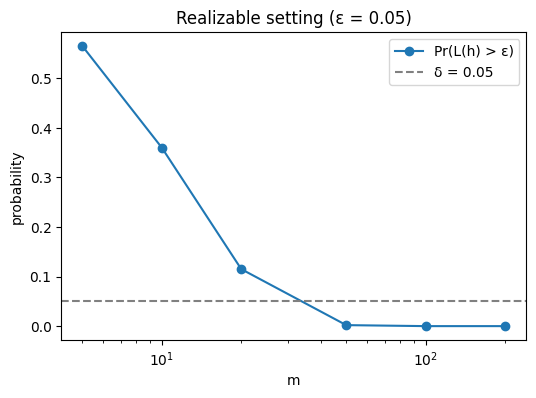

In [8]:
plt.figure(figsize=(6, 4))
plt.plot(SIZES, df_real["Pr(L(h) > ε)"], "o-", label="Pr(L(h) > ε)")
plt.axhline(DELTA, color="gray", ls="--", label=f"δ = {DELTA}")
plt.xscale("log"); plt.xlabel("m"); plt.ylabel("probability")
plt.title(f"Realizable setting (ε = {EPSILON})"); plt.legend(); plt.show()

**Comment.** $\Pr(L(h)>\varepsilon)$ decreases sharply with $m$: about $0.57$ for $m=5$, $0.36$ for $m=10$, $0.12$ for $m=20$, $0.002$ for $m=50$, and $0$ for $m\ge100$. It falls below the confidence level $\delta=0.05$ between $m=20$ and $m=50$, i.e. with a few dozen examples ERM returns, with probability at least $1-\delta$, a hypothesis with true error at most $\varepsilon$: this is exactly the PAC guarantee. The mean true error also decreases roughly like $1/m$ (it is approximately halved each time $m$ doubles), and the empirical error is always $0$.

## 5. From PAC to Agnostic PAC

We repeat the same experiments with label noise $\eta=0.2$. In this setting the best achievable true error is no longer $0$: the best threshold ($t=\theta$) has true error $L^*=\eta$. We therefore estimate two quantities:
- $\Pr(L(h)>\varepsilon)$, as in the realizable setting;
- $\Pr(L(h)-L^*>\varepsilon)$, the agnostic PAC criterion (excess error with respect to the best hypothesis in the class).

In [9]:
emp_noisy, true_noisy = run_experiment(ETA, y_test_noisy)

df_noisy = pd.DataFrame({
    "m": SIZES,
    "mean empirical error": [emp_noisy[m].mean() for m in SIZES],
    "mean true error": [true_noisy[m].mean() for m in SIZES],
    "Pr(empirical error = 0)": [(emp_noisy[m] == 0).mean() for m in SIZES],
    "Pr(L(h) > ε)": [(true_noisy[m] > EPSILON).mean() for m in SIZES],
    "Pr(L(h) − η > ε)": [(true_noisy[m] - ETA > EPSILON).mean() for m in SIZES],
})
df_noisy

,m,mean empirical error,mean true error,Pr(empirical error = 0),Pr(L(h) > ε),Pr(L(h) − η > ε)
0,5,0.114200,0.291621,0.508,1.0,0.630
1,10,0.146300,0.276969,0.174,1.0,0.529
2,20,0.168000,0.249797,0.016,1.0,0.346
3,50,0.187900,0.224082,0.000,1.0,0.152
4,100,0.193660,0.213065,0.000,1.0,0.039
5,200,0.196035,0.206537,0.000,1.0,0.004


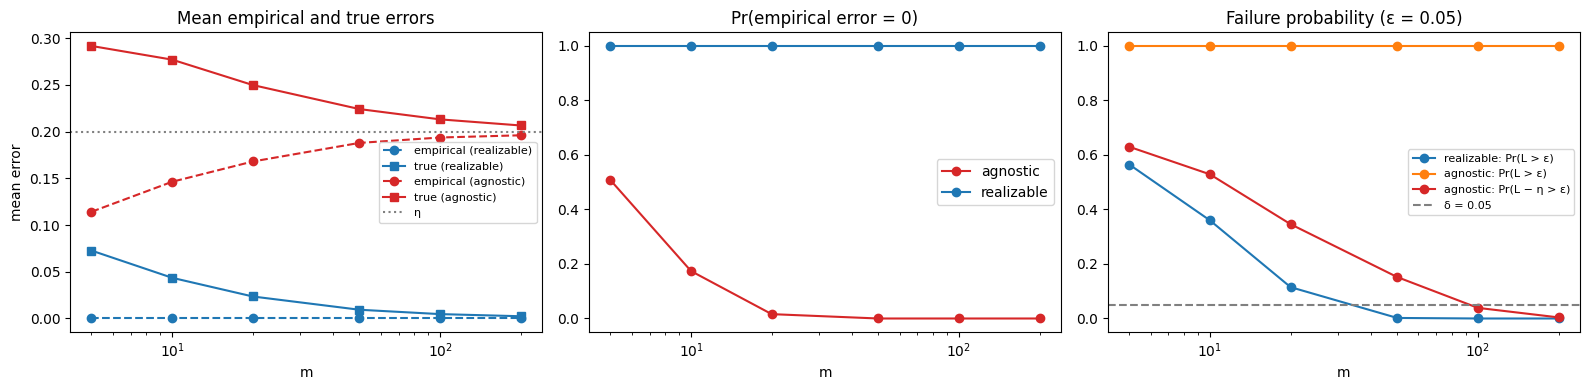

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (a) empirical vs true error
axes[0].plot(SIZES, df_real["mean empirical error"], "o--", c="tab:blue", label="empirical (realizable)")
axes[0].plot(SIZES, df_real["mean true error"], "s-", c="tab:blue", label="true (realizable)")
axes[0].plot(SIZES, df_noisy["mean empirical error"], "o--", c="tab:red", label="empirical (agnostic)")
axes[0].plot(SIZES, df_noisy["mean true error"], "s-", c="tab:red", label="true (agnostic)")
axes[0].axhline(ETA, color="gray", ls=":", label="η")
axes[0].set_xscale("log"); axes[0].set_xlabel("m"); axes[0].set_ylabel("mean error")
axes[0].set_title("Mean empirical and true errors"); axes[0].legend(fontsize=8)

# (b) probability of empirical error = 0
axes[1].plot(SIZES, df_noisy["Pr(empirical error = 0)"], "o-", c="tab:red", label="agnostic")
axes[1].plot(SIZES, [(emp_real[m] == 0).mean() for m in SIZES], "o-", c="tab:blue", label="realizable")
axes[1].set_xscale("log"); axes[1].set_xlabel("m"); axes[1].set_title("Pr(empirical error = 0)"); axes[1].legend()

# (c) probability of a large (excess) error
axes[2].plot(SIZES, df_real["Pr(L(h) > ε)"], "o-", c="tab:blue", label="realizable: Pr(L > ε)")
axes[2].plot(SIZES, df_noisy["Pr(L(h) > ε)"], "o-", c="tab:orange", label="agnostic: Pr(L > ε)")
axes[2].plot(SIZES, df_noisy["Pr(L(h) − η > ε)"], "o-", c="tab:red", label="agnostic: Pr(L − η > ε)")
axes[2].axhline(DELTA, color="gray", ls="--", label=f"δ = {DELTA}")
axes[2].set_xscale("log"); axes[2].set_xlabel("m"); axes[2].set_title(f"Failure probability (ε = {EPSILON})")
axes[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

**Comparison of the realizable and agnostic settings.**

**Can the empirical error still reach zero?** Only for very small samples and by chance: $\Pr(\text{empirical error}=0)$ is about $0.51$ for $m=5$, $0.17$ for $m=10$, $0.02$ for $m=20$ and $0$ for $m\ge50$. The mean empirical error increases with $m$ and approaches $\eta=0.2$ from below (from $0.11$ to $0.196$). A zero empirical error with few samples is overfitting of the noise, and the corresponding true error is large.

**Does increasing the number of training examples still improve generalization?** Yes, but the target changes. The mean true error decreases with $m$ (from $0.29$ to $0.207$) but converges to $\eta$, not to $0$; since $L(h)\ge\eta>\varepsilon$ here, $\Pr(L(h)>\varepsilon)=1$ for every $m$ and the realizable criterion can never be satisfied. What still improves is the excess error: $\Pr(L(h)-\eta>\varepsilon)$ goes from $0.63$ ($m=5$) to $0.15$ ($m=50$), $0.04$ ($m=100$) and $0.004$ ($m=200$). The gap between empirical and true error also shrinks with $m$. Compared with the realizable case, the failure probability drops below $\delta$ later (between $m=50$ and $m=100$ instead of between $m=20$ and $m=50$), so more examples are needed for the same $(\varepsilon,\delta)$.

**Relation to the PAC and Agnostic PAC frameworks.** PAC learning assumes realizability (some $h\in\mathcal H$ has $L(h)=0$) and requires $L(h)\le\varepsilon$ with probability at least $1-\delta$. This is what Section 4 verifies. Agnostic PAC drops this assumption and only requires $L(h)\le\min_{h'\in\mathcal H}L(h')+\varepsilon$ with probability at least $1-\delta$, which is what the excess error $L(h)-\eta$ measures here (the best threshold has error $\eta$). ERM still succeeds in this weaker sense, but it converges more slowly, in line with the larger sample complexity of the agnostic setting.

## Conclusion

In the **PAC (realizable)** setting, ERM reaches zero empirical error, the true error goes to $0$ as $m$ grows, and $\Pr(L(h)>\varepsilon)$ drops below $\delta$ with a few dozen examples ($m=50$ for $\varepsilon=\delta=0.05$). In the **Agnostic PAC** setting with noise $\eta=0.2$, the empirical error cannot stay at zero (it tends to $\eta$), the true error cannot go below $\eta$, and the meaningful guarantee is on the excess error $L(h)-\min_{h'}L(h')$. ERM still learns, since this excess error vanishes as $m$ grows, but it needs more examples than in the realizable case (about $100$ instead of $50$ for the same $\varepsilon$ and $\delta$) and small samples lead to overfitting the noise.